In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")

In [4]:
print("Shape:", df.shape)


Shape: (99224, 7)


In [5]:
display(df.head())

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [7]:
# Missing values
missing = df.isnull().sum()

# Duplicate rows
duplicates = df.duplicated().sum()

# Review score distribution
score_distribution = df["review_score"].value_counts().sort_index()

# Review text availability
text_stats = {
    "title_available": df["review_comment_title"].notna().sum(),
    "message_available": df["review_comment_message"].notna().sum(),
    "both_missing": (
        df["review_comment_title"].isna() &
        df["review_comment_message"].isna()
    ).sum()
}

print("Missing values:\n", missing)
print("\nDuplicates:", duplicates)
print("\nReview score distribution:\n", score_distribution)
print("\nText statistics:\n", text_stats)

Missing values:
 review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Duplicates: 0

Review score distribution:
 review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Text statistics:
 {'title_available': np.int64(11568), 'message_available': np.int64(40977), 'both_missing': np.int64(56518)}


In [9]:
import numpy as np

reviews = df.copy()

title = reviews["review_comment_title"].fillna("").str.strip()
message = reviews["review_comment_message"].fillna("").str.strip()

# Add separator only when both fields contain text
separator = np.where(
    (title != "") & (message != ""),
    ". ",
    ""
)

# Combine title and message
reviews["review_text"] = title + separator + message

# Remove reviews without text
reviews = reviews[reviews["review_text"].str.strip() != ""].copy()

# Check results
print("Original rows:", len(df))
print("Reviews with text:", len(reviews))
print("Missing review_text:", reviews["review_text"].isna().sum())
print("Empty review_text:", (reviews["review_text"] == "").sum())

display(reviews[["review_score", "review_text"]].head(10))

Original rows: 99224
Reviews with text: 42687
Missing review_text: 0
Empty review_text: 0


,review_score,review_text
3,5,Recebi bem antes do prazo estipulado.
4,5,Parabéns lojas lannister adorei comprar pela I...
9,4,recomendo. aparelho eficiente. no site a marca...
12,4,"Mas um pouco ,travando...pelo valor ta Boa."
15,5,"Super recomendo. Vendedor confiável, produto o..."
16,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
19,1,Não chegou meu produto. Péssimo
22,5,Ótimo. Loja nota 10
24,5,obrigado pela atençao amim dispensada
27,5,A compra foi realizada facilmente.\r\nA entreg...


In [11]:
# Calculate text length
reviews["text_length"] = reviews["review_text"].str.len()

# Calculate word count
reviews["word_count"] = reviews["review_text"].str.split().str.len()

# Length statistics
display(
    reviews[["text_length", "word_count"]].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

,text_length,word_count
count,42687.00,42687.00
mean,69.27,11.72
std,54.98,9.69
min,1.00,1.00
25%,27.00,4.00
50%,54.00,9.00
75%,96.00,16.00
90%,162.00,28.00
95%,193.00,33.00
99%,210.14,38.00


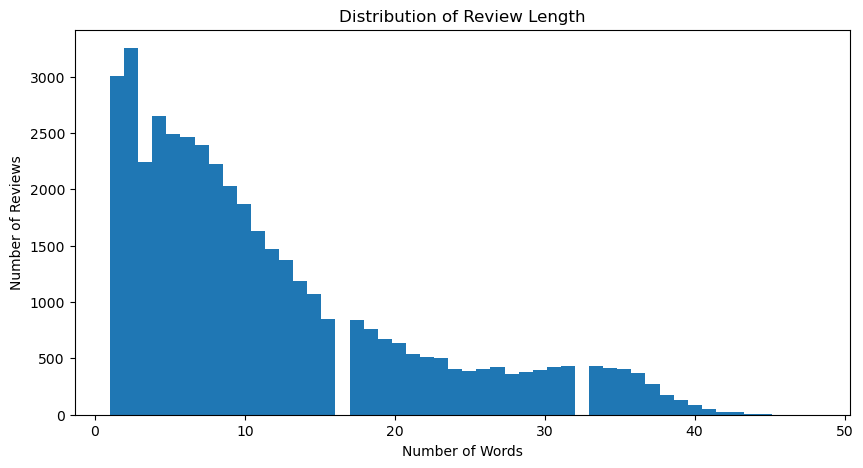

In [12]:
plt.figure(figsize=(10, 5))

plt.hist(reviews["word_count"], bins=50)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [13]:
display(
    reviews.nlargest(10, "word_count")[
        ["review_score", "word_count", "review_text"]
    ]
)

,review_score,word_count,review_text
25464,5,48,Vale a pena. Super adooorei o delineador ele é...
5522,1,46,FALAR C/ATENDENTE NO SAC. Realizei a compra e ...
12826,4,45,Vezzo não é mais o mesmo. Com a venda e a entr...
26343,3,45,Produto bem mais ou menos . Prazo : OK entrega...
40984,1,45,Relógio ruim. Propaganda enganosa lá na descri...
50486,1,45,Nao chegou o produto. Chegou a nota fiscal e n...
67175,1,45,Eu pedi 110 e veio 220 e não consigo fazer a t...
1491,1,44,Atraso na data de entrega. Já entrei em contat...
26815,3,44,Tive problemas. Paguei a mais por que queria d...
41775,4,44,"bom produto, frete caro. não acho o frete dess..."


In [14]:
score_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

display(score_distribution)

display(
    (score_distribution / len(reviews) * 100).round(2)
)

review_score
1     8829
2     2165
3     3643
4     6274
5    21776
Name: count, dtype: int64

review_score
1    20.68
2     5.07
3     8.53
4    14.70
5    51.01
Name: count, dtype: float64